# Week 1 — Dataset Exploration
**MASNN-BCD-HI**: Breast cancer detection from histopathology images

This notebook loads the BreakHis dataset, verifies it matches the paper's reported
statistics (Table 2), and visualizes sample images at each magnification level.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

df = pd.read_csv("../data/splits/split.csv")
df.head()


,path,label,subtype,magnification,patient_id,split
0,data/raw/BreaKHis_v1/BreaKHis_v1/histology_sli...,benign,A,100X,14-22549AB,train
1,data/raw/BreaKHis_v1/BreaKHis_v1/histology_sli...,benign,A,100X,14-22549AB,train
2,data/raw/BreaKHis_v1/BreaKHis_v1/histology_sli...,benign,A,100X,14-22549AB,train
3,data/raw/BreaKHis_v1/BreaKHis_v1/histology_sli...,benign,A,100X,14-22549AB,train
4,data/raw/BreaKHis_v1/BreaKHis_v1/histology_sli...,benign,A,100X,14-22549AB,train


## 1. Class & magnification distribution (compare to paper's Table 2)

In [2]:
summary = df.groupby(["magnification", "label"]).size().unstack(fill_value=0)
summary["total"] = summary.sum(axis=1)
summary.loc["Overall"] = summary.sum()
summary


label,benign,malignant,total
magnification,,,
100X,644,1437,2081
200X,623,1390,2013
400X,588,1232,1820
40X,625,1370,1995
Overall,2480,5429,7909


## 2. Train / val / test split (patient-wise, no leakage)

In [3]:
split_summary = df.groupby(["split", "label"]).size().unstack(fill_value=0)
split_summary["total"] = split_summary.sum(axis=1)
split_summary


label,benign,malignant,total
split,,,
test,250,1032,1282
train,1877,3402,5279
val,353,995,1348


In [4]:
patients_per_split = df.groupby("split")["patient_id"].nunique()
patients_per_split


split
test     13
train    55
val      13
Name: patient_id, dtype: int64

## 3. Sample images at each magnification level

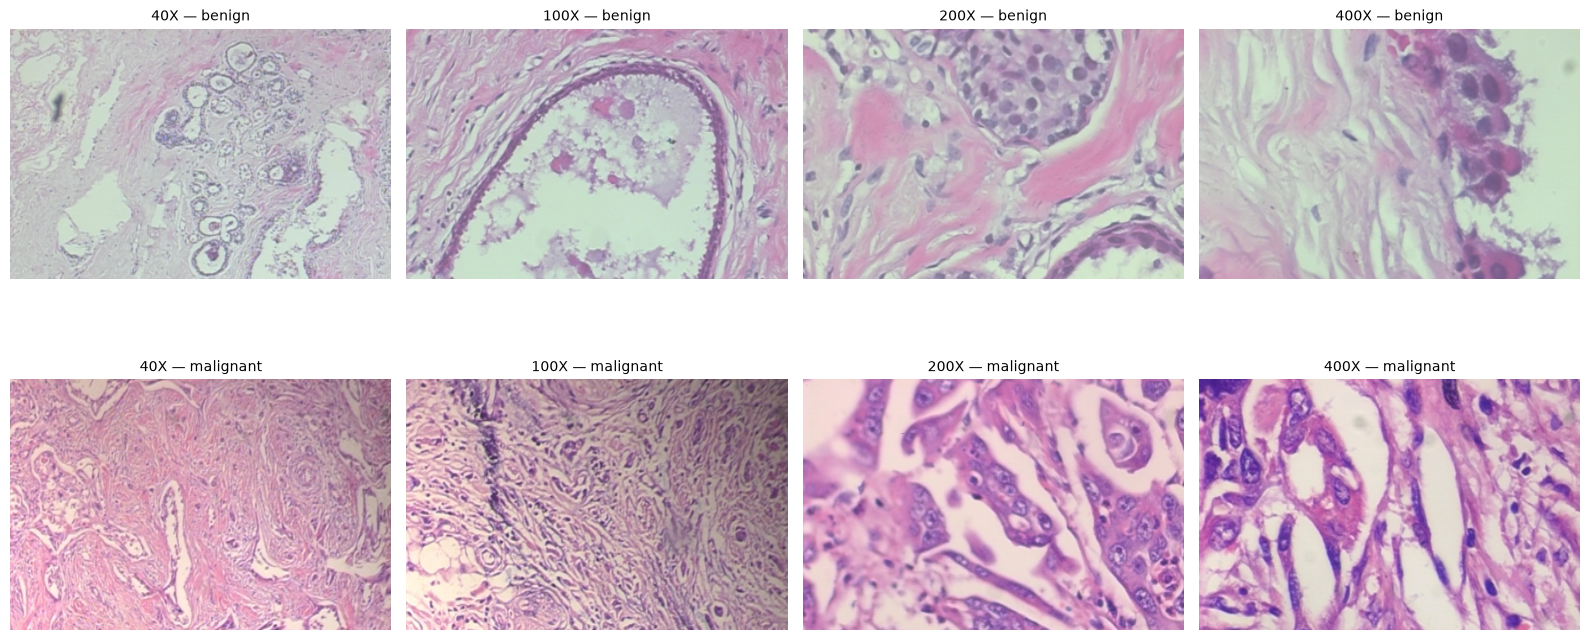

In [5]:
mags = ["40X", "100X", "200X", "400X"]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for col, mag in enumerate(mags):
    for row, label in enumerate(["benign", "malignant"]):
        sample = df[(df.magnification == mag) & (df.label == label)].iloc[0]
        img = Image.open("../" + sample["path"])
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{mag} — {label}", fontsize=10)
        axes[row, col].axis("off")

plt.tight_layout()
plt.savefig("../data/splits/sample_grid.png", dpi=120)
plt.show()


## 4. Why a patient-wise split matters

If we split by *image* instead of by *patient*, photos of the same tissue sample
could appear in both train and test. The model could then partly "recognize" that
specific tissue rather than learn general benign-vs-malignant patterns — inflating
test accuracy in a way that wouldn't hold on truly new patients. We split by
`patient_id` (parsed from the BreakHis filename) so every patient's images stay
entirely within one split.


In [6]:
overlap = set()
for a in ["train", "val", "test"]:
    for b in ["train", "val", "test"]:
        if a >= b:
            continue
        pa = set(df[df.split == a]["patient_id"])
        pb = set(df[df.split == b]["patient_id"])
        overlap |= pa & pb

print("Patients appearing in more than one split:", len(overlap))
assert not overlap


Patients appearing in more than one split: 0
